In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
from sklearn.metrics import roc_auc_score



In [3]:
df = pd.read_csv(r"C:\Users\pranj\OneDrive\Desktop\Customer_Churn_Prediction_using_ANN\customer_churn_dataset-testing-master.csv")

In [4]:
print(df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())

(64374, 12)
   CustomerID  Age  Gender  Tenure  Usage Frequency  Support Calls  \
0           1   22  Female      25               14              4   
1           2   41  Female      28               28              7   
2           3   47    Male      27               10              2   
3           4   35    Male       9               12              5   
4           5   53  Female      58               24              9   

   Payment Delay Subscription Type Contract Length  Total Spend  \
0             27             Basic         Monthly          598   
1             13          Standard         Monthly          584   
2             29           Premium          Annual          757   
3             17           Premium       Quarterly          232   
4              2          Standard          Annual          533   

   Last Interaction  Churn  
0                 9      1  
1                20      0  
2                21      0  
3                18      0  
4                18

In [5]:

print(df.describe())
print(df.nunique())
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)

         CustomerID           Age        Tenure  Usage Frequency  \
count  64374.000000  64374.000000  64374.000000     64374.000000   
mean   32187.500000     41.970982     31.994827        15.080234   
std    18583.317451     13.924911     17.098234         8.816470   
min        1.000000     18.000000      1.000000         1.000000   
25%    16094.250000     30.000000     18.000000         7.000000   
50%    32187.500000     42.000000     33.000000        15.000000   
75%    48280.750000     54.000000     47.000000        23.000000   
max    64374.000000     65.000000     60.000000        30.000000   

       Support Calls  Payment Delay   Total Spend  Last Interaction  \
count   64374.000000   64374.000000  64374.000000      64374.000000   
mean        5.400690      17.133952    541.023379         15.498850   
std         3.114005       8.852211    260.874809          8.638436   
min         0.000000       0.000000    100.000000          1.000000   
25%         3.000000      10.000

In [6]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


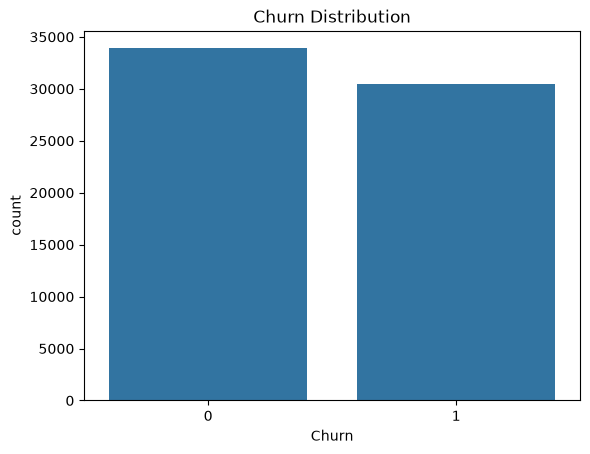

In [7]:
sns.countplot(x="Churn", data=df)
plt.title("Churn Distribution")
plt.show()

In [8]:
print(df.corr(numeric_only=True)["Churn"].sort_values(ascending=False))

Churn               1.000000
Payment Delay       0.557386
CustomerID          0.529832
Support Calls       0.304631
Tenure              0.195327
Age                 0.063457
Last Interaction   -0.002818
Total Spend        -0.078867
Usage Frequency    -0.115098
Name: Churn, dtype: float64


In [9]:
df = df.drop("CustomerID", axis=1)
x=df.drop("Churn", axis=1)
y=df["Churn"]


In [10]:
X = pd.get_dummies(x, drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

sclaer = StandardScaler()

X_train = sclaer.fit_transform(X_train)
X_test = sclaer.transform(X_test)


In [11]:
model = Sequential([
    Dense(64, activation='relu',input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.summary()

c:\Users\pranj\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [14]:
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

Epoch 1/20
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9854 - loss: 0.0349 - val_accuracy: 0.9814 - val_loss: 0.0440
Epoch 2/20
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9865 - loss: 0.0338 - val_accuracy: 0.9794 - val_loss: 0.0531
Epoch 3/20
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9876 - loss: 0.0297 - val_accuracy: 0.9838 - val_loss: 0.0410
Epoch 4/20
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9881 - loss: 0.0293 - val_accuracy: 0.9798 - val_loss: 0.0465
Epoch 5/20
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9883 - loss: 0.0291 - val_accuracy: 0.9841 - val_loss: 0.0372
Epoch 6/20
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9891 - loss: 0.0269 - val_accuracy: 0.9829 - val_loss: 0.0423
Epoch 7/20
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9896 - loss: 0.0265 - val_accuracy: 0.9852 - val_loss: 0.0382
Epoch 8/20
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9907 - loss: 0.0241 - 

In [19]:
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype("int32")

print("accuracy:", accuracy_score(y_test, y_pred_classes))
print("confusion matrix:\n", confusion_matrix(y_test, y_pred_classes))
print("classification report:\n", classification_report(y_test, y_pred_classes))


403/403 ━━━━━━━━━━━━━━━━━━━━ 0s 844us/step
accuracy: 0.9859417475728155
confusion matrix:
 [[6710   66]
 [ 115 5984]]
classification report:
               precision    recall  f1-score   support

           0       0.98      0.99      0.99      6776
           1       0.99      0.98      0.99      6099

    accuracy                           0.99     12875
   macro avg       0.99      0.99      0.99     12875
weighted avg       0.99      0.99      0.99     12875



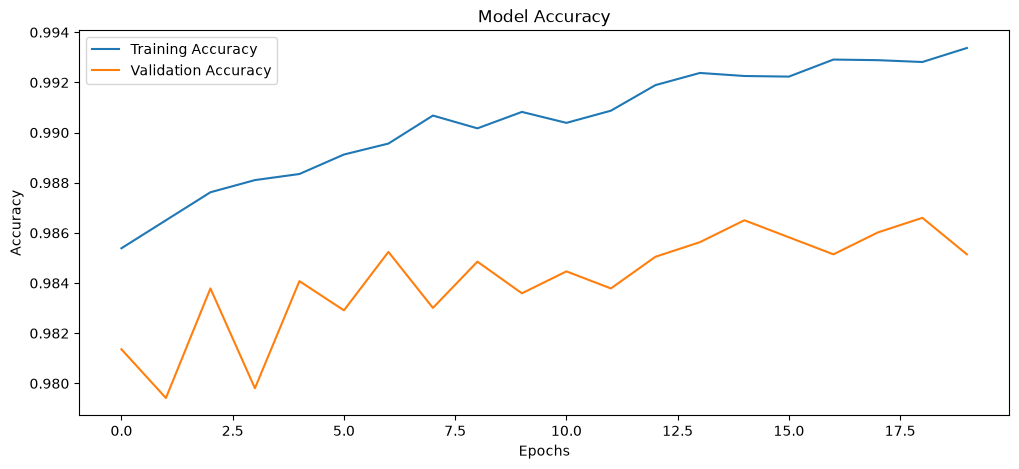

In [20]:
plt.figure(figsize=(12, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

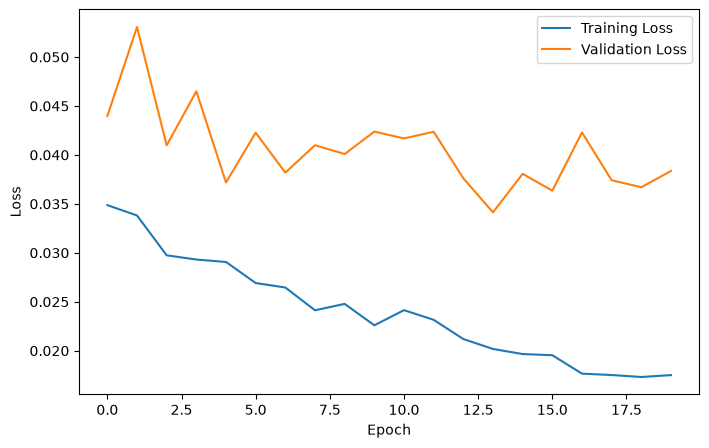

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [23]:
auc = roc_auc_score(y_test, y_pred)
print("AUC Score:", auc)

AUC Score: 0.999384407086303
